In [ ]:

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
DATA_PATH = "/content/drive/MyDrive/salaries.csv"
data = pd.read_csv(
    DATA_PATH
)
data.head()

,company,job,degree,salary_more_than_100k
0,google,sales executive,bachelors,0
1,google,sales executive,masters,0
2,google,business manager,bachelors,1
3,google,business manager,masters,1
4,google,computer programmer,bachelors,0


In [ ]:
input = data.drop('salary_more_than_100k',axis='columns')
input.head()

,company,job,degree
0,google,sales executive,bachelors
1,google,sales executive,masters
2,google,business manager,bachelors
3,google,business manager,masters
4,google,computer programmer,bachelors


In [ ]:
target = data[["salary_more_than_100k"]].copy()
target.head()


,salary_more_than_100k
0,0
1,0
2,1
3,1
4,0


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

le_company = LabelEncoder()
le_job = LabelEncoder()
le_degree = LabelEncoder()

In [ ]:
input["company_n"] = le_company.fit_transform(input["company"])
input["job_n"] = le_job.fit_transform(input["job"])
input["degree_n"] = le_degree.fit_transform(input["degree"])
input.head()

,company,job,degree,company_n,job_n,degree_n
0,2,2,0,2,2,0
1,2,2,1,2,2,1
2,2,0,0,2,0,0
3,2,0,1,2,0,1
4,2,1,0,2,1,0


In [ ]:
input_n = input.drop(['company','job','degree'],axis='columns')
input_n.head()

,company_n,job_n,degree_n
0,2,2,0
1,2,2,1
2,2,0,0
3,2,0,1
4,2,1,0


In [ ]:
model = DecisionTreeClassifier()
model.fit(input_n,target)

DecisionTreeClassifier()

In [ ]:
model.score(input_n,target)

1.0

In [ ]:
model.predict([[2, 2, 0]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(input_n,target,test_size=0.25,random_state=42)
predicted = model.predict(x_test)

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
cm = confusion_matrix(y_test,predicted)
cm

array([[2, 0],
       [0, 2]])

In [ ]:
print("Classification report:",classification_report(y_test,predicted))

Classification report:               precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



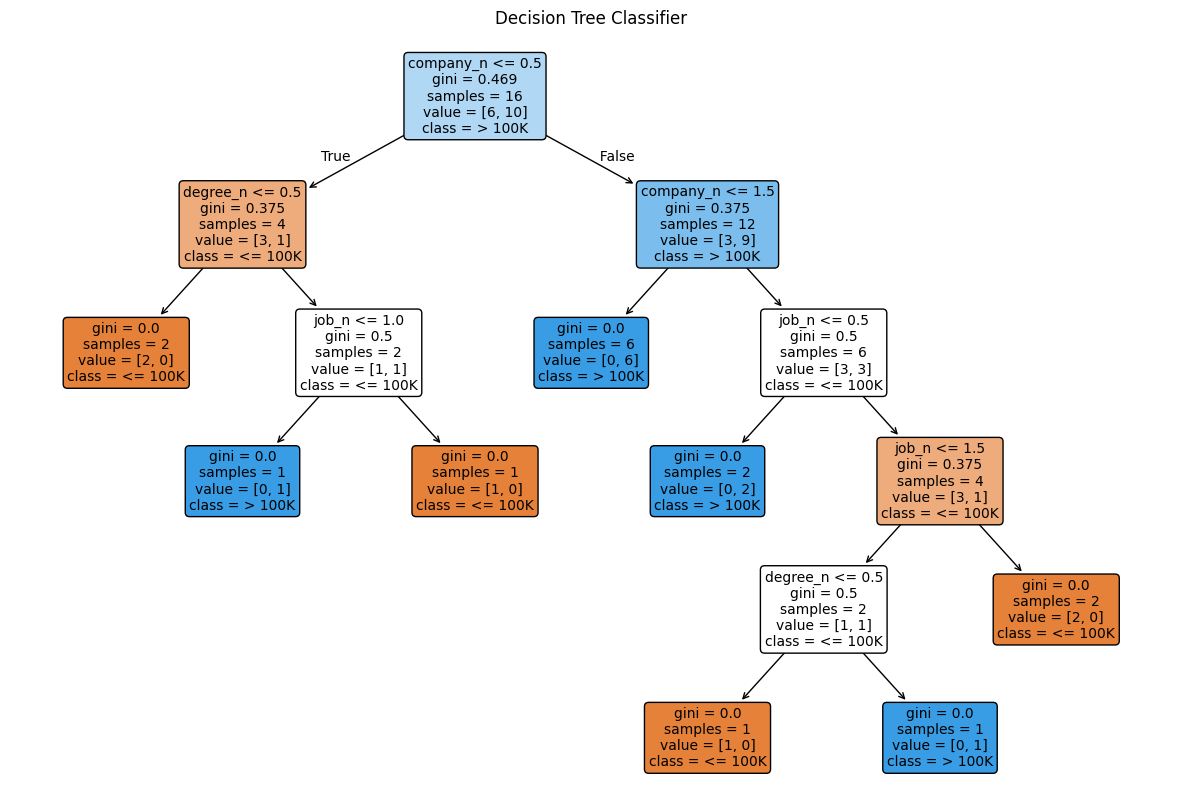

In [ ]:
import matplotlib.pyplot as plt
from sklearn import tree
plt.figure(figsize=(15, 10))
tree.plot_tree(
    model,
    feature_names=input_n.columns,
    class_names=['<= 100K', '> 100K'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Classifier")
plt.show()

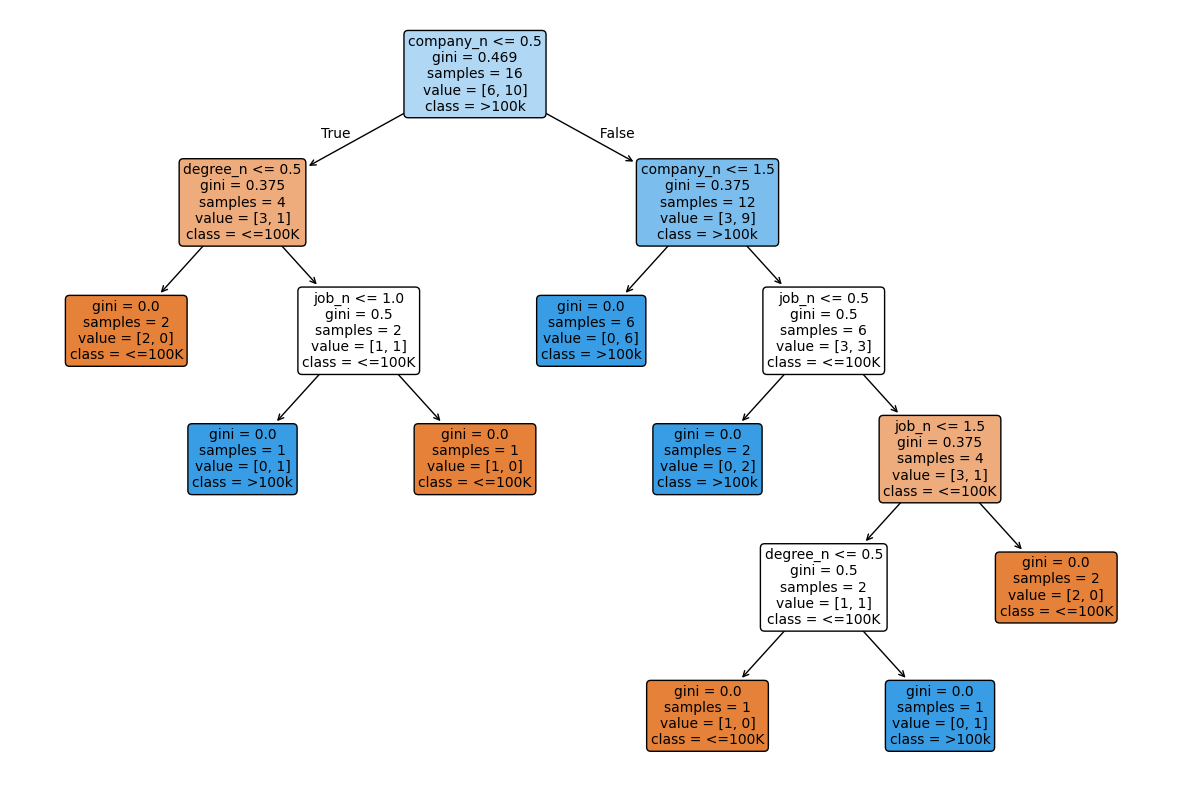

In [ ]:
plt.figure(figsize=(15,10))
tree.plot_tree(
    model,
    feature_names=input_n.columns,
    class_names=['<=100K','>100k'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()